# How rotation is distributed through the SubCellSpace embedding

Simulated cells are rotationally augmented during training, so every simulation exists at
several angles. This notebook asks how much of that orientation survives in the
15-dimensional embedding, and whether it organises the embedding.

Rotation is represented in the embedding, but it is not what the embedding is organised by.
Every rotation angle is spread evenly across the whole UMAP, while the patterns occupy
distinct territories (§1). Rotating a simulation moves its embedding **less** than
re-simulating the same pattern in the same cell at the same transcript count does (0.39
against 0.50 of the distance between two random observations), and about **2.8× less** than
changing the pattern (§2). Clustering is therefore first and foremost separating patterns,
not orientations (Supp. Fig. 5).

Everything below is computed on the **held-out simulated split**: 44,706 images of 64 cells
that the published model never saw during training.

In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import paths
from revbench import controls
from palette import pattern_palette

FIG = paths.figures("rotation")
LATENTS = paths.data("rotation", "arm_a_latents.npz")   # stems + mu of the held-out split
UMAP = paths.data("rotation", "umap.npy")


def encode_heldout(tree, dapi):
    """Rebuild the latent cache: encode every held-out image as mu (needs a GPU).

    `tree` is the held-out split of the rotated simulated images and `dapi` their
    co-rotated nuclei; neither is part of the data bundle, so the cache is shipped.
    """
    from revbench import cvae_encode as ce
    model = ce.load_model(str(paths.MODEL), device="cuda:0")
    stems = sorted(p.name[:-4] for p in tree.glob("*.tif"))
    mu = ce.encode_image_paths(model, [tree / f"{s}.tif" for s in stems],
                               [dapi / f"{s}_DAPI.tif" for s in stems], mode="mu")
    np.savez_compressed(LATENTS, mu=mu, stems=np.array(stems))


def compute_umap(X):
    """Rebuild the UMAP cache with the published neighbourhood size."""
    import anndata as ad, scanpy as sc
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        a = ad.AnnData(X.astype(np.float32))
        sc.pp.neighbors(a, n_neighbors=25, use_rep="X")
        sc.tl.umap(a)
    np.save(UMAP, a.obsm["X_umap"])


lat = np.load(LATENTS, allow_pickle=True)
stems, mu = list(lat["stems"]), lat["mu"]
if not UMAP.exists():
    compute_umap(mu)
emb = np.load(UMAP)
assert len(emb) == len(stems) == len(mu)
print(f"{len(stems):,} held-out images -> {mu.shape[1]}-d latents")

44,706 held-out images -> 15-d latents


In [2]:
# pattern, cell and rotation are parsed from the filename; `it` is the replicate index of a
# simulation, and a family is one simulation (pattern, cell, replicate, proportion, count)
# seen at its different rotation angles
meta = controls.simulated_metadata(stems)
meta["it"] = [int(m.group(1)) if (m := re.search(r"_(\d+)it_", s)) else -1 for s in stems]
meta["family"] = (meta.pattern.astype(str) + "|" + meta.cell_id.astype(str) + "|"
                  + meta.it.astype(str) + "|" + meta.prop.astype(str) + "|"
                  + meta.n_spots.astype(str))
PATTERNS = ["cell-edge", "extranuclear", "intranuclear", "pericellular",
            "perinuclear", "random"]

PCOL = pattern_palette()          # the paper's pattern colours
ANGLE_CMAP = "twilight"           # cyclic, so 0 deg and 355 deg sit next to each other
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2df"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED, "axes.edgecolor": GRID, "font.size": 9,
    "axes.titlesize": 10, "figure.dpi": 120, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False,
})

## 1. Every rotation angle covers the whole map

Colouring the embedding by pattern gives clear territories; colouring the same
points by rotation angle gives no structure at all.

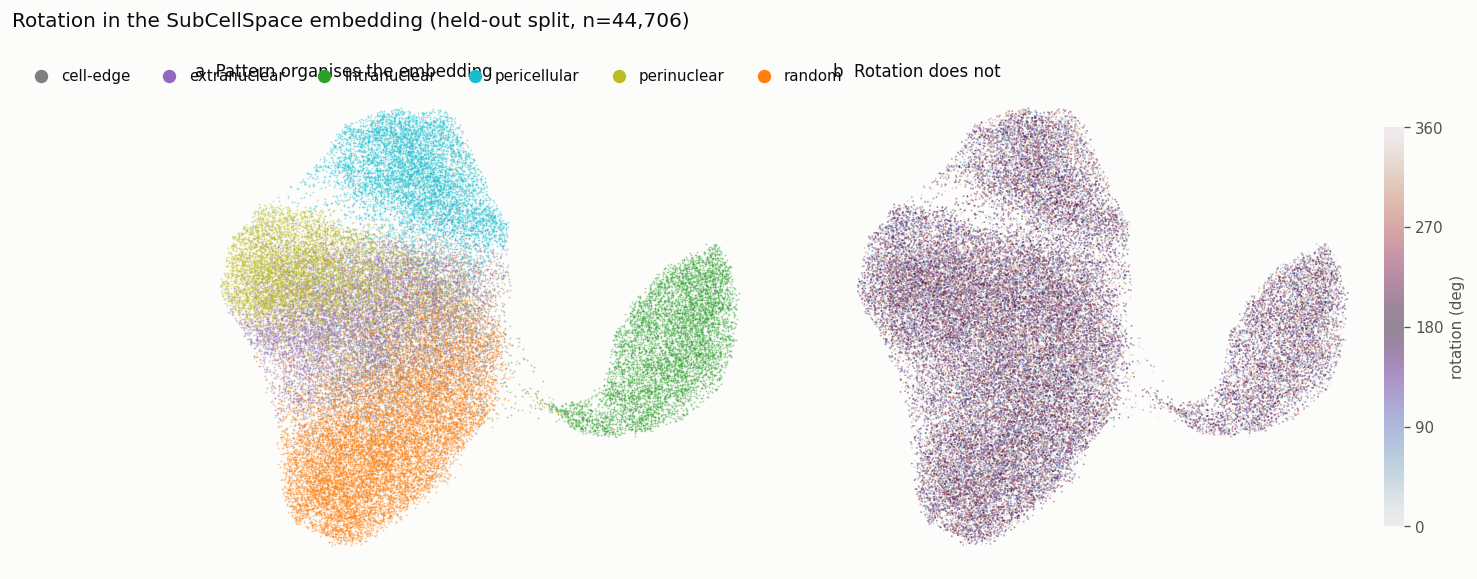

In [3]:
def fig_umap():
    order = np.random.RandomState(101).permutation(len(emb))
    pat = meta.pattern.astype(str).values
    rot = meta.rotation.astype(float).values

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"wspace": 0.12})
    for p in PATTERNS:
        m = pat[order] == p
        ax.scatter(*emb[order][m].T, s=1.2, c=PCOL[p], alpha=0.45, linewidths=0,
                   rasterized=True)
    ax.set_title("a  Pattern organises the embedding", loc="left", color=INK)

    sc_ = ax2.scatter(*emb[order].T, s=1.2, c=rot[order] % 360, cmap=ANGLE_CMAP,
                      vmin=0, vmax=360, alpha=0.5, linewidths=0, rasterized=True)
    cb = fig.colorbar(sc_, ax=ax2, fraction=0.035, pad=0.02,
                      ticks=[0, 90, 180, 270, 360])
    cb.set_label("rotation (deg)", color=INK_MUTED); cb.outline.set_visible(False)
    ax2.set_title("b  Rotation does not", loc="left", color=INK)

    for a in (ax, ax2):
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values(): s.set_visible(False)
    fig.legend(handles=[Line2D([], [], marker="o", ls="", markersize=7, color=PCOL[p],
                               label=p) for p in PATTERNS],
               loc="upper left", bbox_to_anchor=(0.008, 0.93), ncol=6, fontsize=9,
               handletextpad=0.35, columnspacing=1.6)
    fig.suptitle(f"Rotation in the SubCellSpace embedding (held-out split, "
                 f"n={len(emb):,})", x=0.008, ha="left", fontsize=12, color=INK, y=1.0)
    fig.savefig(FIG / "fig1_umap.png", bbox_inches="tight", dpi=170)

fig_umap(); plt.show()

## 2. How far rotation moves a cell, against what else could move it

Each bar is the mean distance in the 15-dimensional latent between pairs of
observations that differ in exactly one respect, divided by the mean distance
between two random observations. Rotation is the smallest of the four: it moves a
cell's embedding less than simply re-running the same simulation at the same
transcript count, and far less than changing the pattern.

Pairs are drawn with one seeded random stream (seed 101), up to 200,000 per comparison.
Rotated pairs and count-matched re-simulations are enumerated completely where the groups
are small enough; the other comparisons are sampled with groups weighted by their size.

In [4]:
N_PAIRS = 200_000
SEED = 101


def _within_group_pairs(groups, rng, cap=N_PAIRS):
    """All within-group index pairs (subsampled to `cap`)."""
    groups = np.asarray(groups)
    order = np.argsort(groups, kind="stable")
    gs = groups[order]
    bounds = np.flatnonzero(np.r_[True, gs[1:] != gs[:-1], True])
    a, b = [], []
    for s, e in zip(bounds[:-1], bounds[1:]):
        mem = order[s:e]
        if len(mem) < 2:
            continue
        ii, jj = np.triu_indices(len(mem), k=1)
        a.append(mem[ii]); b.append(mem[jj])
    a, b = np.concatenate(a), np.concatenate(b)
    if len(a) > cap:
        pick = rng.choice(len(a), cap, replace=False)
        a, b = a[pick], b[pick]
    return a, b


def _matched_pairs(key_same, key_diff, rng, n=N_PAIRS):
    """Random pairs sharing `key_same` but differing on `key_diff`, groups weighted by size."""
    key_same, key_diff = np.asarray(key_same), np.asarray(key_diff)
    order = np.argsort(key_same, kind="stable")
    ks = key_same[order]
    bounds = np.flatnonzero(np.r_[True, ks[1:] != ks[:-1], True])
    groups = [order[s:e] for s, e in zip(bounds[:-1], bounds[1:]) if e - s > 1]
    probs = np.array([len(g) for g in groups], float)
    probs /= probs.sum()
    a, b, tries = [], [], 0
    while sum(len(x) for x in a) < n and tries < 40:
        tries += 1
        gi = rng.choice(len(groups), max(n, 1024), p=probs)
        for g in np.unique(gi):
            pool = groups[g]
            m = int((gi == g).sum())
            i = pool[rng.randint(0, len(pool), m)]
            j = pool[rng.randint(0, len(pool), m)]
            keep = (i != j) & (key_diff[i] != key_diff[j])
            a.append(i[keep]); b.append(j[keep])
    a, b = np.concatenate(a), np.concatenate(b)
    return a[:n], b[:n]


def _cross_subgroup_pairs(key_same, key_diff, rng, cap=N_PAIRS):
    """Every pair sharing `key_same` but differing on `key_diff`, enumerated (subsampled to `cap`)."""
    key_same, key_diff = np.asarray(key_same), np.asarray(key_diff)
    order = np.argsort(key_same, kind="stable")
    ks = key_same[order]
    bounds = np.flatnonzero(np.r_[True, ks[1:] != ks[:-1], True])
    a, b = [], []
    for s, e in zip(bounds[:-1], bounds[1:]):
        pos = order[s:e]
        if len(pos) < 2:
            continue
        ii, jj = np.triu_indices(len(pos), k=1)
        m = key_diff[pos[ii]] != key_diff[pos[jj]]
        if m.any():
            a.append(pos[ii][m]); b.append(pos[jj][m])
    a, b = np.concatenate(a), np.concatenate(b)
    if len(a) > cap:
        pick = rng.choice(len(a), cap, replace=False)
        a, b = a[pick], b[pick]
    return a, b


def distance_ladder(mu, meta):
    rng = np.random.RandomState(SEED)
    pattern = meta.pattern.astype(str).values
    cell = meta.cell_id.astype(str).values
    pat_cell = pd.Series(pattern) + "|" + pd.Series(cell)
    dist = lambda a, b: np.linalg.norm(mu[a] - mu[b], axis=1)

    ia, ib = rng.randint(0, len(mu), N_PAIRS), rng.randint(0, len(mu), N_PAIRS)
    keep = ia != ib
    scale = dist(ia[keep], ib[keep]).mean()

    rows = []
    def add(key, label, a, b):
        rows.append({"key": key, "comparison": label, "distance": dist(a, b).mean() / scale,
                     "n_pairs": len(a)})
    add("r1", "rotated: same simulation,\ndifferent angle",
        *_within_group_pairs(meta.family.values, rng))
    # re-simulation without matching the transcript count: not shown, but drawn so the
    # seeded stream (and every comparison after it) stays the same
    add("r2", "re-simulated: same pattern and cell",
        *_cross_subgroup_pairs(pat_cell.values, meta.it.values, rng))
    add("r2b", "re-simulated: same pattern, cell\nand transcript count",
        *_cross_subgroup_pairs((pat_cell + "|" + meta.n_spots.astype(str)).values,
                               meta.it.values, rng))
    add("r3", "a different cell,\nsame pattern", *_matched_pairs(pattern, cell, rng))
    add("r4", "a different pattern,\nsame cell", *_matched_pairs(cell, pattern, rng))
    return pd.DataFrame(rows).set_index("key")


ladder = distance_ladder(mu, meta).loc[["r1", "r2b", "r3", "r4"]].reset_index(drop=True)
ladder

,comparison,distance,n_pairs
0,"rotated: same simulation,\ndifferent angle",0.389364,57269
1,"re-simulated: same pattern, cell\nand transcri...",0.502740,30340
2,"a different cell,\nsame pattern",0.616082,200000
3,"a different pattern,\nsame cell",1.077493,200000


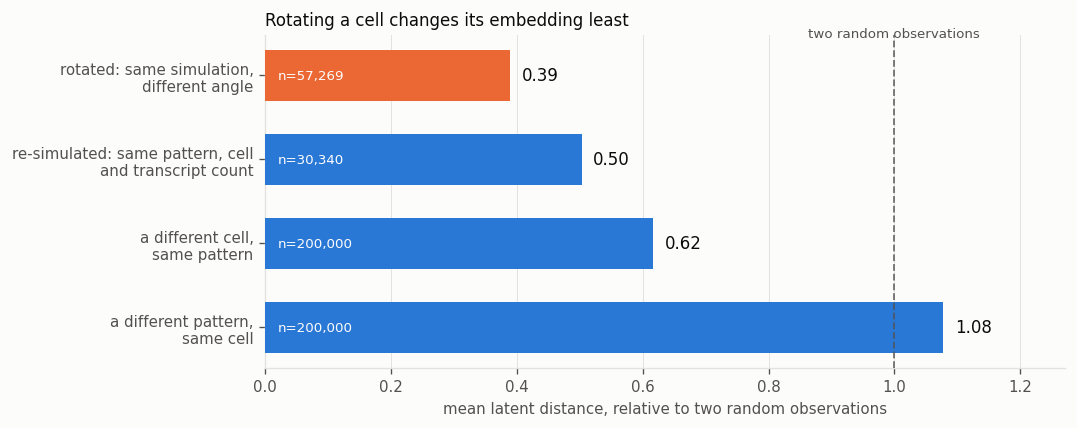

In [5]:
def fig_ladder():
    fig, ax = plt.subplots(figsize=(8.6, 3.6))
    y = np.arange(len(ladder))[::-1]
    cols = ["#eb6834"] + ["#2a78d6"] * 3
    ax.barh(y, ladder["distance"], 0.6, color=cols, zorder=3)
    for yi, r in zip(y, ladder.itertuples()):
        ax.annotate(f"{r.distance:.2f}", (r.distance, yi), textcoords="offset points",
                    xytext=(7, 0), va="center", fontsize=10, color=INK)
        ax.annotate(f"n={r.n_pairs:,}", (0.02, yi), va="center", fontsize=8,
                    color=SURFACE)
    ax.set_yticks(y); ax.set_yticklabels(ladder["comparison"], fontsize=9)
    ax.set_xlabel("mean latent distance, relative to two random observations")
    ax.set_xlim(0, ladder["distance"].max() * 1.18)
    ax.axvline(1.0, color=INK_MUTED, lw=1.1, ls="--", alpha=0.8, zorder=5)
    ax.annotate("two random observations", (1.0, y.max() + 0.42), ha="center",
                va="bottom", fontsize=8, color=INK_MUTED)
    ax.set_title("Rotating a cell changes its embedding least", loc="left", color=INK)
    ax.grid(True, axis="x", color=GRID, lw=0.6, zorder=0); ax.set_axisbelow(True)
    fig.savefig(FIG / "fig2_ladder.png", bbox_inches="tight", dpi=170)

fig_ladder(); plt.show()

## In short

Orientation is present in the embedding but plays a minor role: it is the smallest
of the factors compared, and it forms no axis or gradient that a UMAP could
display. The structure visible in an embedding corresponds to **pattern**, and
rotations of the same cell appear as local scatter within a cluster rather than as
movement across the map.

Practically, pattern identity can be read off the embedding directly, while any
orientation-specific question should be asked within a set of comparable cells
rather than globally.

## Supp. Fig. 5

The supplementary page, drawn from the UMAP and the distance ladder above.

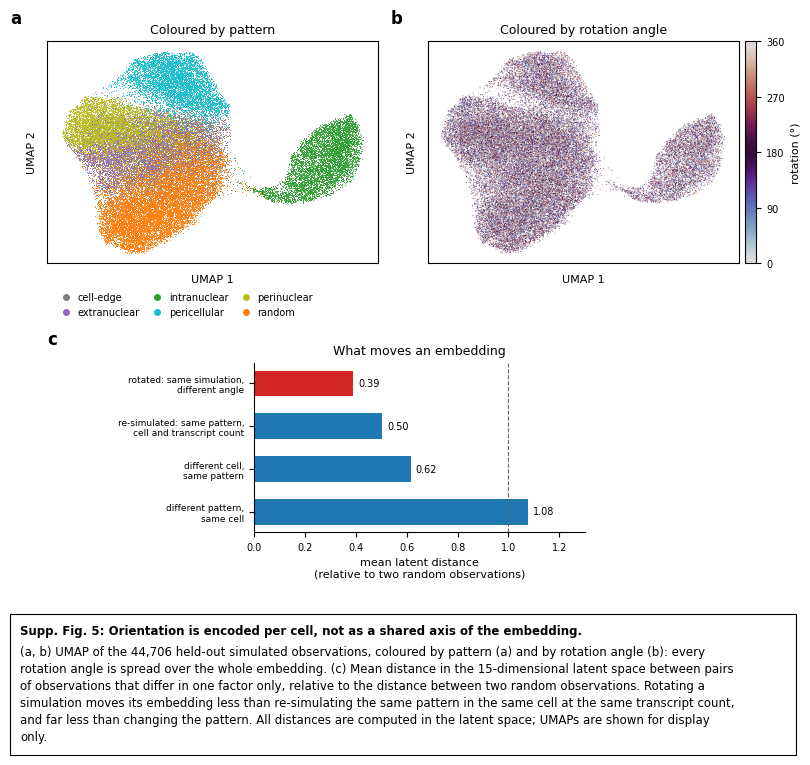

In [6]:
from supp_style import new_page, panel_letter, caption_box, save_page, COL

rot = meta.rotation.astype(float).values % 360
pattern = meta.pattern.astype(str).values
order = np.random.RandomState(101).permutation(len(emb))

fig = new_page()
pt = dict(s=0.4, linewidths=0, rasterized=True)

# a: by pattern, b: by angle
ax_a = fig.add_axes([0.07, 0.775, 0.40, 0.19])
for p in PATTERNS:
    m = pattern[order] == p
    ax_a.scatter(*emb[order][m].T, c=COL[p], **pt)
ax_a.set_title("Coloured by pattern")
ax_a.legend(handles=[Line2D([], [], marker="o", ls="", ms=4, color=COL[p], label=p) for p in PATTERNS],
            loc="upper left", bbox_to_anchor=(0, -0.09), ncol=3, frameon=False, handletextpad=0.2, columnspacing=0.8)
ax_b = fig.add_axes([0.53, 0.775, 0.40, 0.19])
sc = ax_b.scatter(*emb[order].T, c=rot[order], cmap="twilight", vmin=0, vmax=360, **pt)
cb = fig.colorbar(sc, ax=ax_b, fraction=0.04, pad=0.02, ticks=[0, 90, 180, 270, 360])
cb.set_label("rotation (°)")
ax_b.set_title("Coloured by rotation angle")
for ax in (ax_a, ax_b):
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
panel_letter(fig, ax_a, "a"); panel_letter(fig, ax_b, "b")

# c: distance ladder (§2)
labels = ["rotated: same simulation,\ndifferent angle",
          "re-simulated: same pattern,\ncell and transcript count",
          "different cell,\nsame pattern",
          "different pattern,\nsame cell"]
rows = list(zip(labels, ladder["distance"]))
ax_c = fig.add_axes([0.32, 0.545, 0.40, 0.145])
y = np.arange(len(rows))[::-1]
ax_c.barh(y, [v for _, v in rows], color=["#d62728"] + ["#1f77b4"] * 3, height=0.6)
for yi, (_, v) in zip(y, rows):
    ax_c.text(v + 0.02, yi, f"{v:.2f}", va="center", fontsize=7)
ax_c.set_yticks(y); ax_c.set_yticklabels([l for l, _ in rows], fontsize=6.5)
ax_c.axvline(1.0, color="0.4", ls="--", lw=0.8)
ax_c.set_xlim(0, 1.3)
ax_c.set_xlabel("mean latent distance\n(relative to two random observations)")
ax_c.set_title("What moves an embedding")
ax_c.spines[["top", "right"]].set_visible(False)
panel_letter(fig, ax_c, "c", dx=-0.25)

caption_box(fig, 0.475,
    "Supp. Fig. 5: Orientation is encoded per cell, not as a shared axis of the embedding.",
    "(a, b) UMAP of the 44,706 held-out simulated observations, coloured by pattern (a) and by rotation angle (b): "
    "every rotation angle is spread over the whole embedding. (c) Mean distance in the 15-dimensional latent space "
    "between pairs of observations that differ in one factor only, relative to the distance between two random "
    "observations. Rotating a simulation moves its embedding less than re-simulating the same pattern in the same "
    "cell at the same transcript count, and far less than changing the pattern. All distances are computed in the "
    "latent space; UMAPs are shown for display only.")
save_page(fig, "5_rotation_in_latent_space_total")
fig